In [1]:
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval dataeval-plots maite-datasets
except Exception:
    pass

In [2]:
import dataeval_plots as dep
import numpy as np
import polars as pl
from maite_datasets.image_classification import MilitaryVehicles

from dataeval import Metadata
from dataeval.bias import Balance, Diversity
from dataeval.core import image_stats
from dataeval.flags import ImageStats

dep.set_default_backend("matplotlib")

In [3]:
train_ds = MilitaryVehicles("./data", image_set="train", download=True, lazy=True)
metadata = Metadata(train_ds)
print(f"Factor names: {metadata.factor_names}")

Factor names: []


In [4]:
# Calculate pixel and visual statistics
calc_results = image_stats(train_ds, stats=ImageStats.PIXEL | ImageStats.VISUAL)

# Append the factors to the metadata and drop the constant one
metadata.add_factors(calc_results)
metadata.exclude = ["missing"]
print(f"Factor names: {metadata.factor_names}")

Factor names: ['brightness', 'contrast', 'darkness', 'entropy', 'kurtosis', 'mean', 'saturation', 'sharpness', 'skew', 'std', 'var', 'zeros']


In [5]:
keys = (
    "mean",
    "std",
    "var",
    "skew",
    "kurtosis",
    "entropy",
    "saturation",
    "brightness",
    "darkness",
    "sharpness",
    "contrast",
    "zeros",
)
values = {key: np.asarray(calc_results["stats"][key], dtype=float) for key in keys}
# Cut at the quantiles, with infinite outer edges so that the largest value falls in the last bin
quantile_edges = {key: [-np.inf, *np.unique(np.quantile(values[key], [0.2, 0.4, 0.6, 0.8])), np.inf] for key in keys}


def busiest_bin(key: str, edges: list[float] | np.ndarray) -> float:
    """Share of the images that fall in the most crowded bin."""
    return float(np.histogram(values[key], edges)[0].max() / len(values[key]))


for key in ("kurtosis", "zeros"):
    equal_width = busiest_bin(key, np.linspace(values[key].min(), values[key].max(), 6))
    print(
        f"{key:>8}: busiest bin holds {equal_width:.1%} of the images with equal-width bins, "
        f"{busiest_bin(key, quantile_edges[key]):.1%} with equal-count bins"
    )

kurtosis: busiest bin holds 99.2% of the images with equal-width bins, 20.0% with equal-count bins
   zeros: busiest bin holds 98.5% of the images with equal-width bins, 20.0% with equal-count bins


In [6]:
metadata.continuous_factor_bins = quantile_edges

In [7]:
balance_output = Balance().evaluate(metadata)

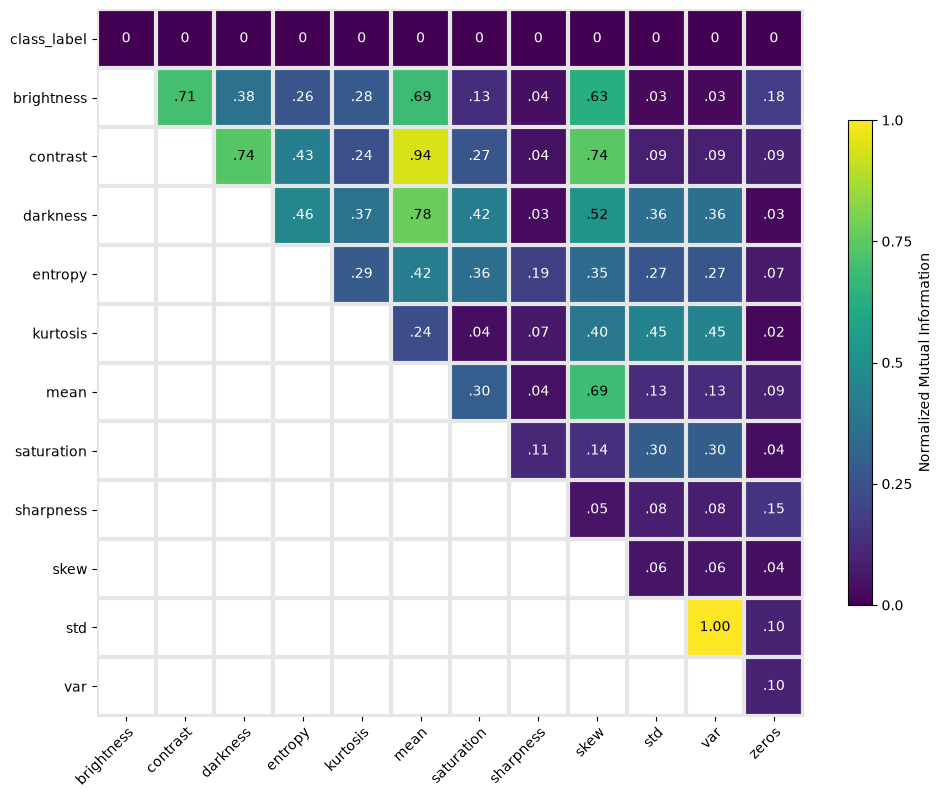

In [8]:
dep.plot(balance_output)

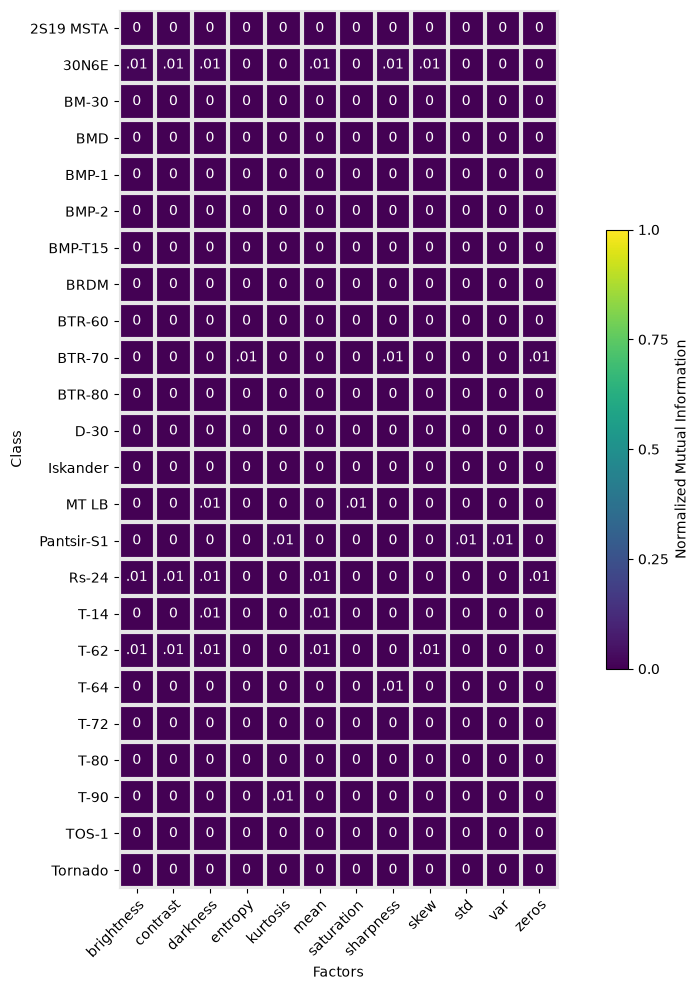

In [9]:
dep.plot(balance_output, plot_classwise=True)

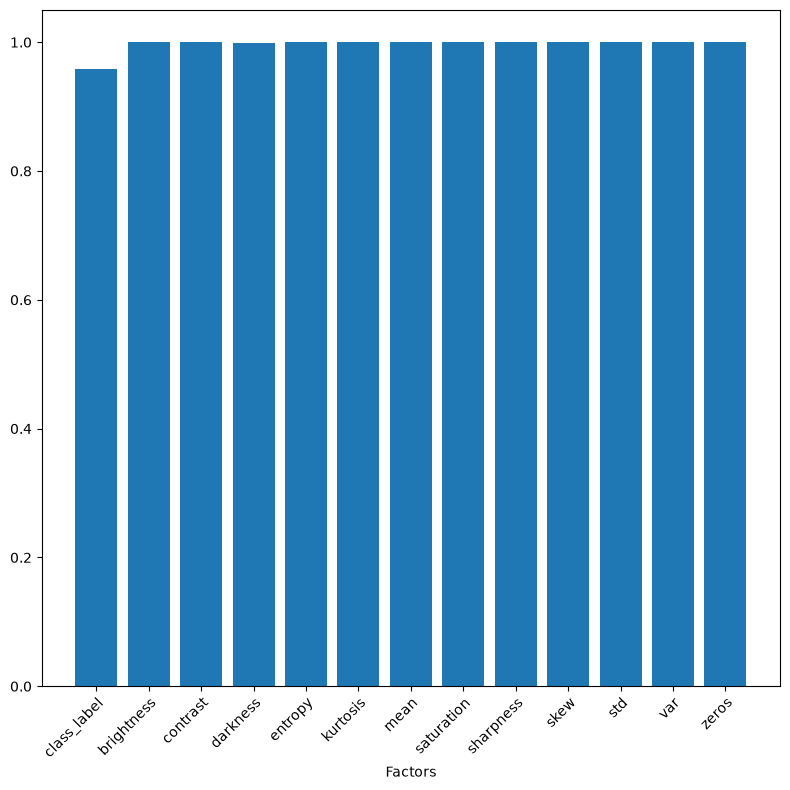

In [10]:
diversity_output = Diversity().evaluate(metadata)
dep.plot(diversity_output)

In [11]:
width_metadata = Metadata(train_ds)
width_metadata.add_factors(calc_results)
width_metadata.exclude = ["missing"]
width_metadata.continuous_factor_bins = dict.fromkeys(keys, 5)

width_diversity = Diversity().evaluate(width_metadata).factors
for key in ("kurtosis", "zeros"):
    print(f"{key:>8}: diversity {width_diversity.filter(pl.col('factor_name') == key)['diversity_value'][0]:.3f}")

kurtosis: diversity 0.006
   zeros: diversity 0.008


In [12]:
# TEST ASSERTION CELL ###
assert metadata.factor_names == sorted(keys)
assert np.all(np.asarray(calc_results["stats"]["missing"]) == 0)
assert busiest_bin("kurtosis", np.linspace(values["kurtosis"].min(), values["kurtosis"].max(), 6)) > 0.99
assert busiest_bin("kurtosis", quantile_edges["kurtosis"]) < 0.25

pairs = balance_output.factors
assert pairs.filter((pl.col("factor1") == "std") & (pl.col("factor2") == "var"))["mi_value"][0] > 0.99
assert abs(pairs.filter((pl.col("factor1") == "contrast") & (pl.col("factor2") == "mean"))["mi_value"][0] - 0.94) < 0.02
assert abs(pairs.filter((pl.col("factor1") == "darkness") & (pl.col("factor2") == "mean"))["mi_value"][0] - 0.78) < 0.03
assert (balance_output.balance["mi_value"][1:] < 0.01).all()  # "zero throughout"
largest_classwise = float(balance_output.classwise["mi_value"].to_numpy().max())
assert abs(largest_classwise - 0.015) < 0.003  # "the largest value is 0.015"
assert balance_output.classwise.sort("mi_value")["class_name"][-1] == "30N6E"
assert not balance_output.classwise["is_imbalanced"].any()

counts = np.bincount(metadata.class_labels)
assert (counts.min(), counts.max()) == (119, 424)
spread = diversity_output.factors
assert abs(spread.filter(pl.col("factor_name") == "class_label")["diversity_value"][0] - 0.96) < 0.01
for key in keys:
    assert spread.filter(pl.col("factor_name") == key)["diversity_value"][0] > 0.999  # "reads 1.00"
assert 0.10 < np.mean(values["darkness"] == 255) < 0.11  # "a tenth of these photographs"
for key in ("kurtosis", "zeros"):
    assert width_diversity.filter(pl.col("factor_name") == key)["diversity_value"][0] < 0.01